# 2 次のハイパスフィルタ(サレン・キー)

[2 次の LPF](01_sk_lpf.ipynb) の R と C を入れ替えた **2 次の HPF** です。低い周波数を −40 dB/decade で落とします。Q の意味は LPF と同じです。

この回では、Q を変えたボード線図、方形波、1 次と 2 次の HPF で低い周波数の取り除き方を比べます。

## 回路

![サレン・キーの HPF](02_sk_hpf/circuit.svg)

コンデンサ 2 個は同じ値 C にします。R1 は出力に、R2 は信号のグランド(Mimic の Vref)につなぎます。

## 原理

$$H(f) = \frac{-(f/f_c)^2}{1 - (f/f_c)^2 + j\,\dfrac{f/f_c}{Q}}, \qquad f_c = \frac{1}{2\pi C\sqrt{R_1 R_2}}, \qquad Q = \frac{1}{2}\sqrt{\frac{R_2}{R_1}}$$

| 周波数 | 振幅 | 位相 |
|---|---|---|
| $f \ll f_c$ | $(f / f_c)^2$(周波数が 1/10 で 1/100、+40 dB/dec) | +180° に近づく(進む) |
| $f = f_c$ | **Q** | +90° |
| $f \gg f_c$ | 1 | 0° |

![2 次の HPF の周波数特性(模式図)](02_sk_hpf/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路(C が同じ値) |
|---|---|---|
| `lab.mimic.biquad_hpf(fc, q)` | `mimic.setFilterBiquadHPF(fc, Q)` | $R_1 = \dfrac{1}{2Q \cdot 2\pi f_c C}$、$R_2 = \dfrac{2Q}{2\pi f_c C}$ |

例:$f_c$ = 100 Hz、Q = 0.707 は、C = 100 nF、R1 = 11 kΩ、R2 = 22 kΩ の回路にあたります。

## 準備:測定器につなぐ

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, Monitor, fit_sine, match_phase, plot_waveforms

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

In [2]:
FC = 100  # cutoff frequency [Hz]

def bode_axes(title):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax1.set_title(title)
    ax1.set_ylabel("Gain [dB]")
    ax2.set_ylabel("Phase [deg]")
    ax2.set_xlabel("Frequency [Hz]")
    for ax in (ax1, ax2):
        ax.grid(True, which="both", alpha=0.4)
    return fig, ax1, ax2


def second_order(f, fc, q, kind):
    # Response of the module: lpf 1/D, hpf s^2/D, bpf (s/Q)/D, notch (s^2 + 1)/D
    s = 1j * f / fc
    d = s * s + s / q + 1
    return {"lpf": 1, "hpf": s * s, "bpf": s / q, "notch": s * s + 1}[kind] / d

## 実験 1:Q を変えたボード線図

Q = 0.5、0.707、2 で測ります。破線は 1 次の HPF(同じ $f_c$)です。

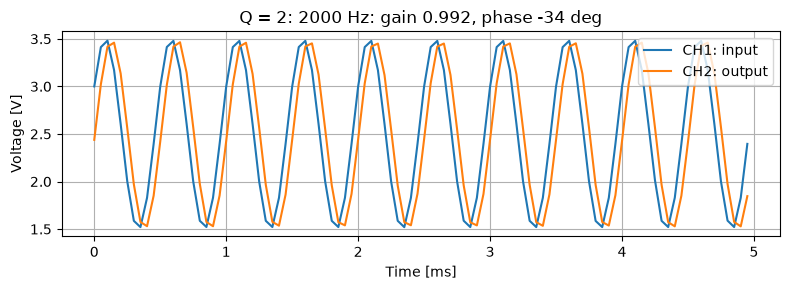

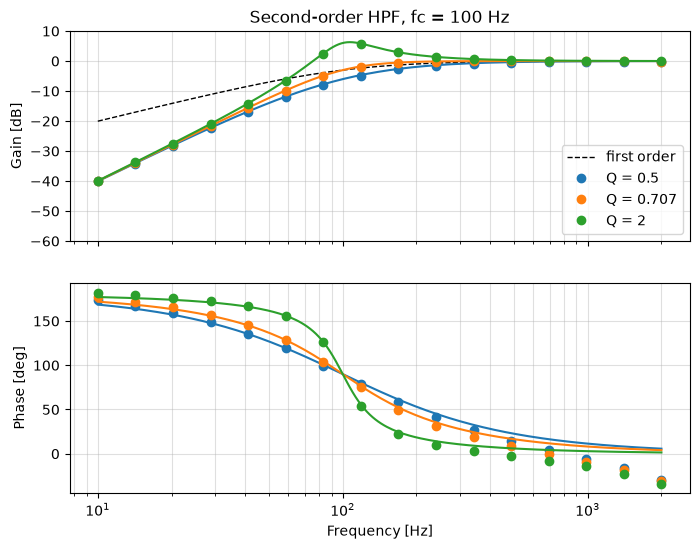

In [3]:
freqs = np.logspace(1, np.log10(2000), 16)   # 10 Hz - 2 kHz
f_th = np.logspace(1, np.log10(2000), 200)
fig, ax1, ax2 = bode_axes(f"Second-order HPF, fc = {FC} Hz")
h1 = (1j * f_th / FC) / (1 + 1j * f_th / FC)
ax1.semilogx(f_th, 20 * np.log10(abs(h1)), "k--", lw=1, label="first order")
rs = {}
mon = Monitor()  # one plot updated while measuring
for i, q in enumerate([0.5, 0.707, 2]):
    lab.mimic.biquad_hpf(FC, q)
    r = rs[q] = lab.frequency_response(freqs, monitor=mon, label=f"Q = {q}: ")
    h = second_order(f_th, FC, q, "hpf")
    ax1.semilogx(f_th, 20 * np.log10(abs(h)), "-", color=f"C{i}")
    ax2.semilogx(f_th, np.degrees(np.unwrap(np.angle(h))), "-", color=f"C{i}")
    ax1.semilogx(r.freq, r.gain_db, "o", color=f"C{i}", label=f"Q = {q}")
    ax2.semilogx(r.freq, match_phase(r.phase, np.degrees(np.unwrap(np.angle(second_order(r.freq, FC, q, "hpf"))))), "o", color=f"C{i}")
ax1.set_ylim(-60, 10)
ax1.legend()
mon.close()
plt.show()

各周波数で取り込んだ波形です(クリックで開きます)。


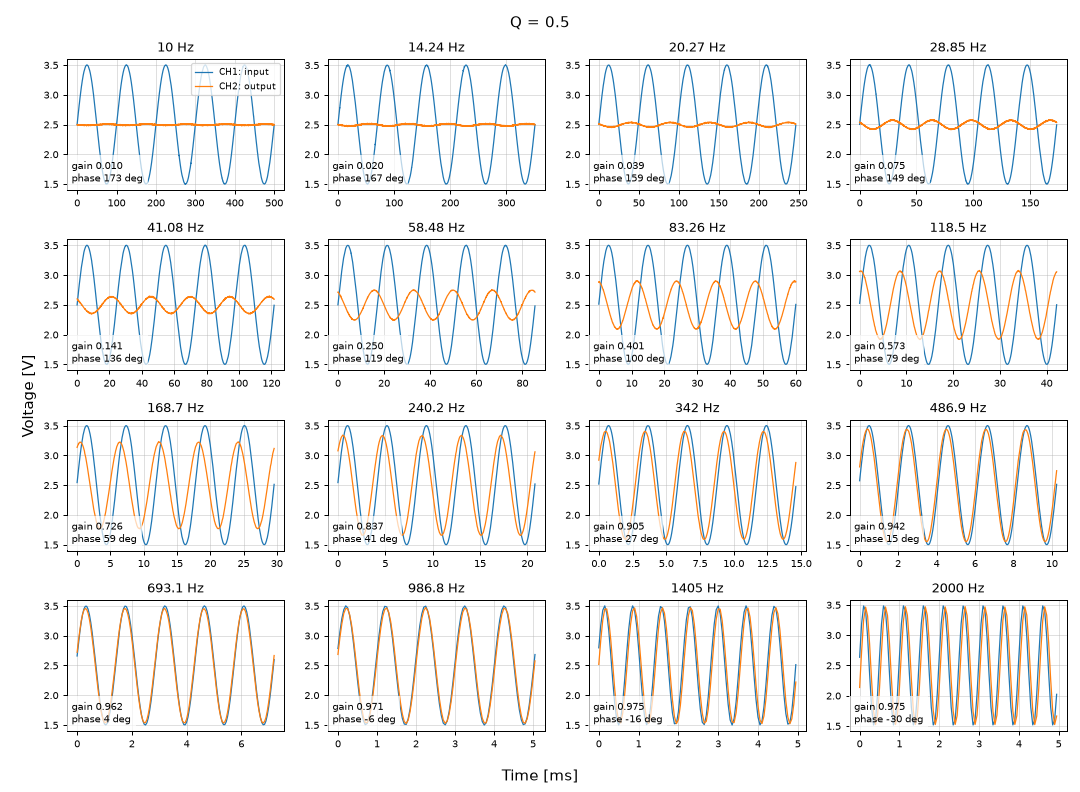


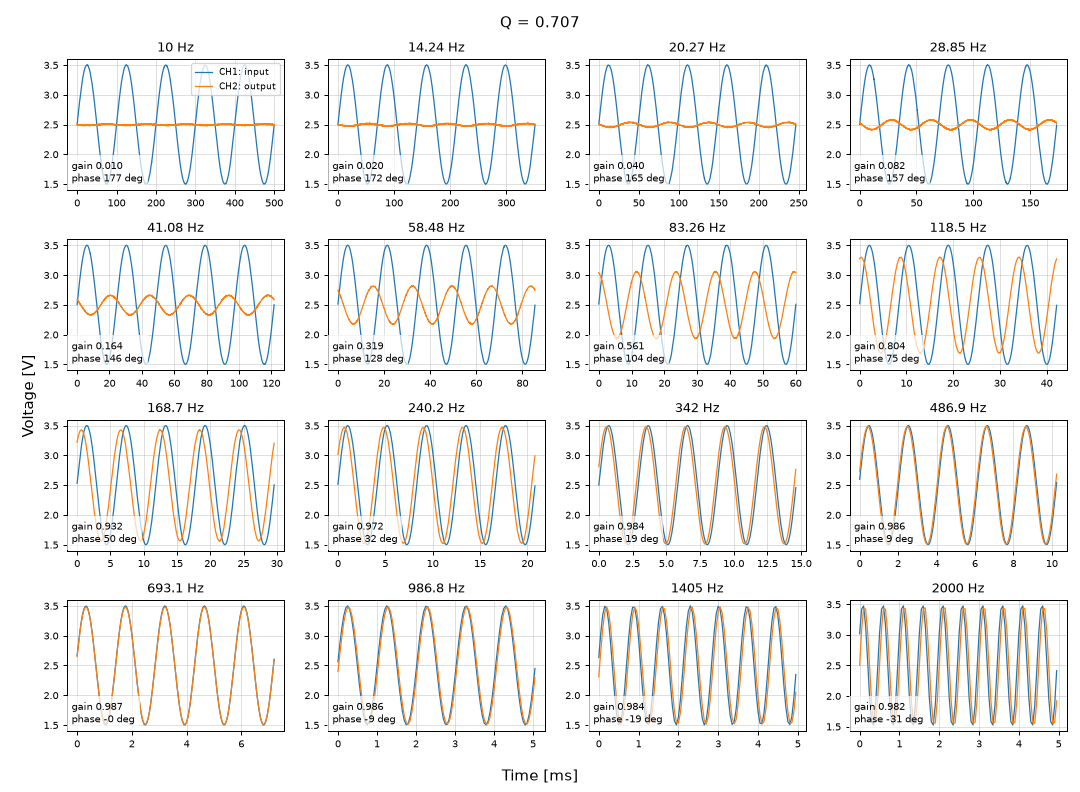


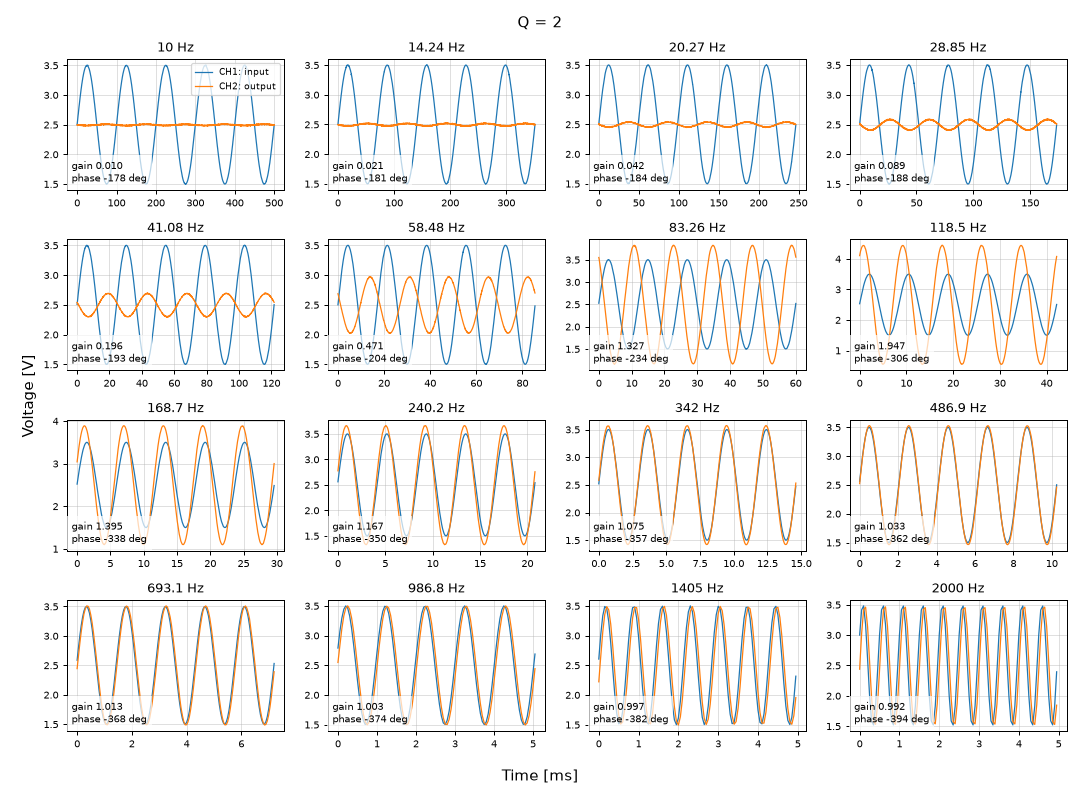

In [4]:
for key, r in rs.items():
    plot_waveforms(r, title=f"Q = {key}", collapsed=True)

## 実験 2:方形波を入れる

20 Hz の方形波を入れます。切り替わりで跳ねたあと Vref に戻るのは 1 次の HPF と同じですが、2 次では戻るときに Vref を**行き過ぎて**反対側に出ます。Q が大きいほど、大きく振動します。

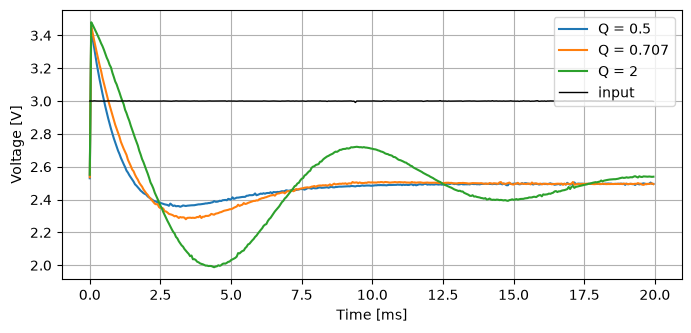

In [5]:
lab.fg.square(20, 0.5)  # 0.5 V peak: the jumps stay inside the supply
fig, ax = plt.subplots(figsize=(8, 3.5))
for i, q in enumerate([0.5, 0.707, 2]):
    lab.mimic.biquad_hpf(FC, q)
    t, ch1, ch2 = lab.scope.capture(400)  # 20 ms
    ax.plot(t * 1e3, ch2, color=f"C{i}", label=f"Q = {q}")
ax.plot(t * 1e3, ch1, "k", lw=1, label="input")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## 実験 3:1 次と 2 次で比べる

10 Hz($f_c$ の 1/10)の正弦波を入れます。1 次の HPF では振幅が約 1/10 になりますが、2 次(Q = 0.707)では約 1/100 まで小さくなります。ゆっくりした変化(例えば、温度による直流のずれ)を、しっかり取り除きたいときは 2 次を使います。

first order : gain 0.0984
second order: gain 0.0099


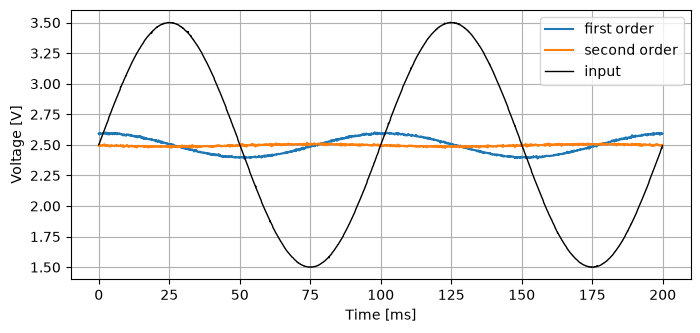

In [6]:
lab.fg.sine(10, 1.0)
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, setup in [("first order", lambda: lab.mimic.filter1st_hpf(FC)),
                     ("second order", lambda: lab.mimic.biquad_hpf(FC))]:
    setup()
    t, ch1, ch2 = lab.scope.capture(2000, fs=10000)  # 0.2 s: two periods
    a1, p1, c1 = fit_sine(t, ch1, 10)
    a2, p2, c2 = fit_sine(t, ch2, 10)
    print(f"{label:12s}: gain {a2 / a1:.4f}")
    ax.plot(t * 1e3, ch2, label=label)
ax.plot(t * 1e3, ch1, "k", lw=1, label="input")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

理論は 1 次で 0.0995、2 次(バターワース)で 0.0100 です。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. Q を変えて方形波を入れる
<details><summary>ヒント</summary>

`Q_TRY` を 0.577 → 1 → 5 と変えてみましょう。Q が大きいほど、跳ねたあとに Vref のまわりで長く振動します。振動の周波数は、LPF と同じくほぼ $f_c$ です。

</details>

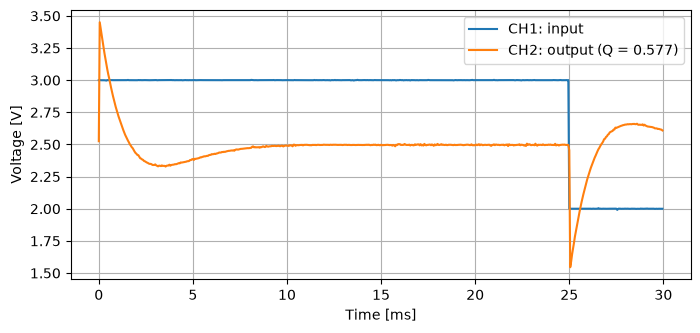

In [7]:
Q_TRY = 0.577

import time
lab.mimic.biquad_hpf(FC, Q_TRY)
lab.fg.square(20, 0.5)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(600)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (Q = {Q_TRY})")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. 1 次と 2 次を、ほかの周波数で比べる

実験 3 を、別の周波数でやってみます。理論の値を計算してから確かめます。
<details><summary>ヒント</summary>

`ORDER` を 1 → 2 と変え、次に `F_TEST` を 30 → 50 に変えて、また 1 → 2 と試してみましょう。$x = f/f_c$ として、1 次は $x/\sqrt{1+x^2}$、2 次(バターワース)は $x^2/\sqrt{1+x^4}$ です。30 Hz なら 0.287 と 0.090、50 Hz なら 0.447 と 0.243 です。$f_c$ から離れるほど、2 次との差が大きくなります。

</details>

order 1, 30 Hz: gain 0.2845 (theory 0.2873)


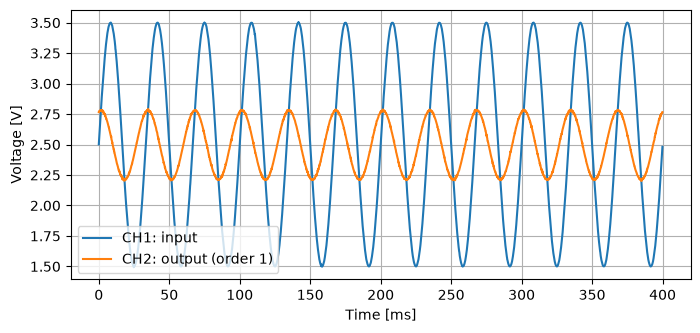

In [8]:
ORDER = 1     # 1 or 2
F_TEST = 30   # [Hz]

import time
if ORDER == 1:
    lab.mimic.filter1st_hpf(FC)
else:
    lab.mimic.biquad_hpf(FC)
lab.fg.sine(F_TEST, 1.0)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(4000, fs=10000)
a1, _, _ = fit_sine(t, ch1, F_TEST)
a2, _, _ = fit_sine(t, ch2, F_TEST)
x = F_TEST / FC
theory = x / np.sqrt(1 + x ** 2) if ORDER == 1 else x ** 2 / np.sqrt(1 + x ** 4)
print(f"order {ORDER}, {F_TEST} Hz: gain {a2 / a1:.4f} (theory {theory:.4f})")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (order {ORDER})")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- 2 次の HPF は、$f_c$ より下を −40 dB/decade で落とす。$f_c$ でのゲインは Q。
- 方形波では、跳ねたあと Vref を行き過ぎて振動する(Q が大きいほど強い)。
- サレン・キー回路では、C が同じなら $f_c = 1/(2\pi C\sqrt{R_1R_2})$、$Q = \frac{1}{2}\sqrt{R_2/R_1}$。Mimic では `biquad_hpf(fc, q)`。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()